# Estudio Estadístico del Comportamiento del Nivel del Río Magdalena (2010 - 2026).

In [40]:
# Importamos las librerias necesarias

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
# Cargamos y mostramos el dataset 1

data1 = pd.read_csv("nivel_honda_tolima.csv")
data1.head()

,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion
0,23017020,BOCATOMA [23017020],NIVEL,Nivel medio mensual,2010-01-01 00:00,cm,115.0,Preliminar
1,23017020,BOCATOMA [23017020],NIVEL,Nivel medio mensual,2010-02-01 00:00,cm,99.0,Preliminar
2,23017020,BOCATOMA [23017020],NIVEL,Nivel medio mensual,2010-03-01 00:00,cm,109.0,Preliminar
3,23017020,BOCATOMA [23017020],NIVEL,Nivel medio mensual,2010-04-01 00:00,cm,133.0,Preliminar
4,23017020,BOCATOMA [23017020],NIVEL,Nivel medio mensual,2010-05-01 00:00,cm,135.0,Preliminar


In [42]:
# Cargamos y mostramos el dataset 2

data2 = pd.read_csv("nivel_suan_atlantico.csv")
data2.head()

,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion
0,29047070,SAN PEDRITO - AUT [29047070],NIVEL,Nivel medio mensual,2010-01-01 00:00,cm,249.0,Preliminar
1,29047070,SAN PEDRITO - AUT [29047070],NIVEL,Nivel medio mensual,2010-02-01 00:00,cm,152.0,Preliminar
2,29047070,SAN PEDRITO - AUT [29047070],NIVEL,Nivel medio mensual,2010-03-01 00:00,cm,239.0,Preliminar
3,29047070,SAN PEDRITO - AUT [29047070],NIVEL,Nivel medio mensual,2010-04-01 00:00,cm,351.0,Preliminar
4,29047070,SAN PEDRITO - AUT [29047070],NIVEL,Nivel medio mensual,2010-05-01 00:00,cm,523.0,Preliminar


In [43]:
# Unimos los 2 dataset para crear un solo dataframe con la columna Municipio

data1['Municipio'] = 'Honda'
data2['Municipio'] = 'Suan'

df_consolidado = pd.concat([data1, data2], ignore_index=True)
df_consolidado.head()

,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion,Municipio
0,23017020,BOCATOMA [23017020],NIVEL,Nivel medio mensual,2010-01-01 00:00,cm,115.0,Preliminar,Honda
1,23017020,BOCATOMA [23017020],NIVEL,Nivel medio mensual,2010-02-01 00:00,cm,99.0,Preliminar,Honda
2,23017020,BOCATOMA [23017020],NIVEL,Nivel medio mensual,2010-03-01 00:00,cm,109.0,Preliminar,Honda
3,23017020,BOCATOMA [23017020],NIVEL,Nivel medio mensual,2010-04-01 00:00,cm,133.0,Preliminar,Honda
4,23017020,BOCATOMA [23017020],NIVEL,Nivel medio mensual,2010-05-01 00:00,cm,135.0,Preliminar,Honda


In [44]:
# Usamos la función describe para ver los datos estadísticos

df_consolidado.groupby('Municipio')['Valor'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Municipio,,,,,,,,
Honda,189.0,136.77,17.02,87.41,128.00,140.37,148.81,177.22
Suan,198.0,514.45,166.86,130.85,402.16,508.00,626.43,908.00


C:\Users\soporte.sistemas\AppData\Local\Temp\ipykernel_17804\3701639762.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Municipio', y='Valor', data=df_consolidado, palette='Set2')


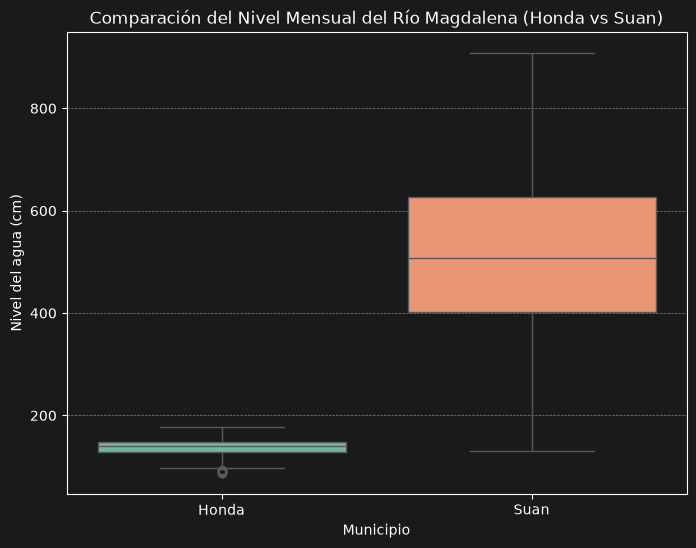

In [45]:
# Aseguramos la fecha en formato datatime y graficamos boxplot para comparar los niveles

df_consolidado['Fecha'] = pd.to_datetime(df_consolidado['Fecha'])

plt.figure(figsize=(8, 6))
sns.boxplot(x='Municipio', y='Valor', data=df_consolidado, palette='Set2')
plt.title('Comparación del Nivel Mensual del Río Magdalena (Honda vs Suan)')
plt.ylabel('Nivel del agua (cm)')
plt.xlabel('Municipio')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

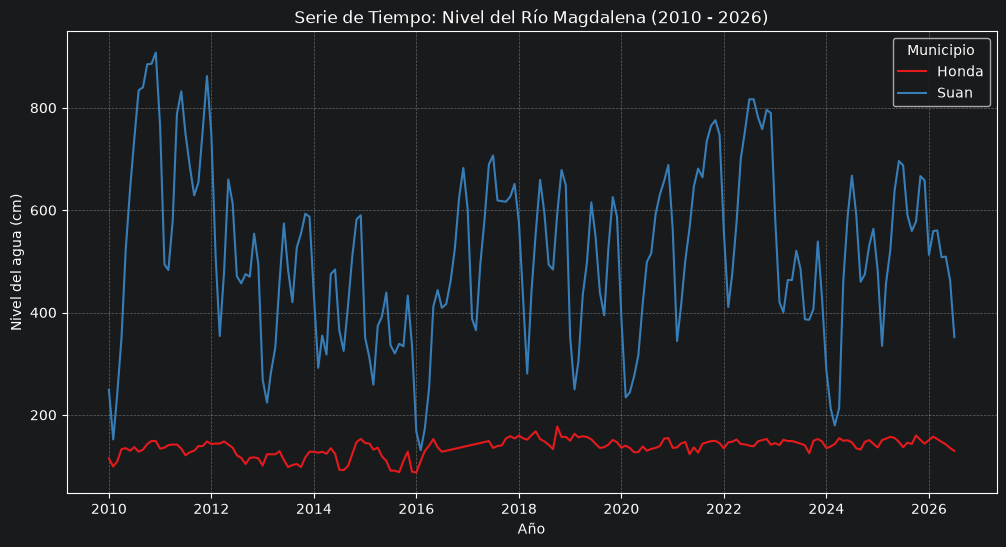

In [46]:
# Gráfico de línea para ver la evolución histórica

plt.figure(figsize=(12, 6))
sns.lineplot(x='Fecha', y='Valor', hue='Municipio', data=df_consolidado, palette='Set1')
plt.title('Serie de Tiempo: Nivel del Río Magdalena (2010 - 2026)')
plt.ylabel('Nivel del agua (cm)')
plt.xlabel('Año')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Conclusiones Principales del Análisis:

Acumulación y Magnitud: El Río Magdalena maneja un volumen de agua significativamente mayor en su cuenca baja (Suan,\
media de 514.45 cm) en comparación con su cuenca media (Honda, media de 136.77 cm), lo que evidencia la acumulación\
progresiva de caudales a lo largo de su recorrido hacia el Atlántico.

Estabilidad vs. Volatilidad: Mientras Honda mantiene una alta estabilidad hídrica histórica (desviación estándar de\
solo 17.02 cm), Suan presenta una volatilidad extrema (desviación de 166.86 cm). Esta marcada fluctuación refleja\
fuertemente los ciclos estacionales de lluvia y sequía del país.

Sensibilidad a Eventos Extremos: La cuenca baja es altamente susceptible a desbordamientos causados por fenómenos\
macro climáticos (como La Niña), alcanzando picos históricos de hasta 908.00 cm. En contraste, la cuenca media absorbe\
 estas variaciones con menor turbulencia, registrando valores atípicos asociados principalmente a sequías anómalas\
 (mínimo de 87.41 cm).

In [47]:
# Extraemos el mes de la columna fecha
df_consolidado['Mes'] = df_consolidado['Fecha'].dt.month

In [48]:
# Calculamos el promedio histórico para cada mes
estacionalidad = df_consolidado.groupby(['Mes', 'Municipio'])['Valor'].mean().reset_index()

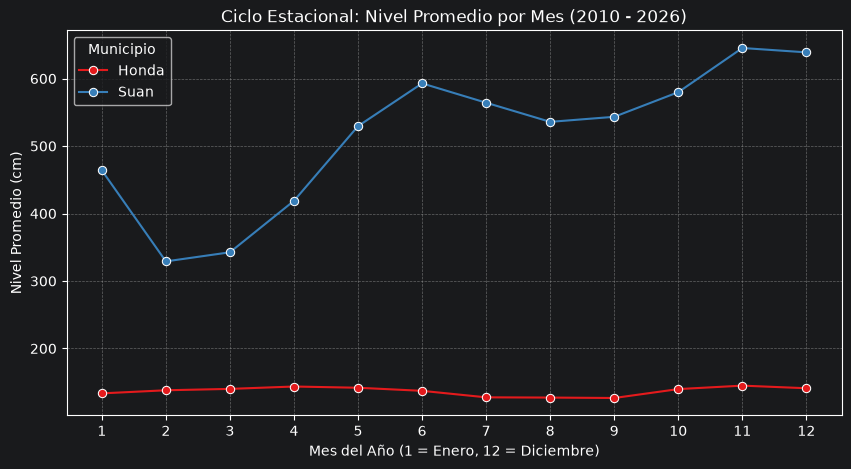

In [49]:
plt.figure(figsize=(10, 5))
sns.lineplot(x='Mes', y='Valor', hue='Municipio', data=estacionalidad, marker='o', palette='Set1')
plt.title('Ciclo Estacional: Nivel Promedio por Mes (2010 - 2026)')
plt.ylabel('Nivel Promedio (cm)')
plt.xlabel('Mes del Año (1 = Enero, 12 = Diciembre)')
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Ciclo Estacional Promedio: El análisis mensual histórico demuestra patrones opuestos en la cuenca del Río Magdalena.\
El municipio de Honda (línea roja) exhibe un comportamiento notablemente constante a lo largo del año, con niveles\
promedio que se mantienen estables alrededor de los 130-150 cm. Por el contrario, Suan (línea azul) revela una\
fuerte dependencia estacional, marcando su época de estiaje (niveles más bajos) entre febrero y marzo, y\
experimentando un incremento sostenido que alcanza su pico máximo histórico de caudal en el mes de noviembre\
(superando los 600 cm en promedio).

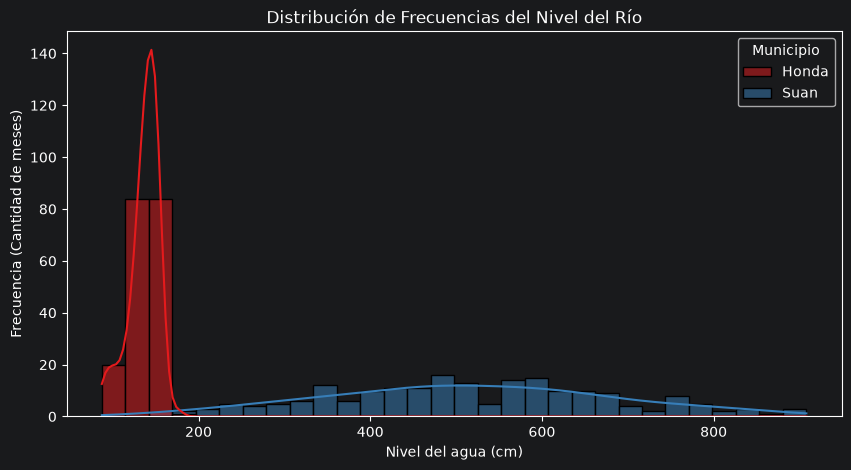

In [50]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df_consolidado, x='Valor', hue='Municipio', kde=True, bins=30, palette='Set1', alpha=0.5)
plt.title('Distribución de Frecuencias del Nivel del Río')
plt.xlabel('Nivel del agua (cm)')
plt.ylabel('Frecuencia (Cantidad de meses)')
plt.show()

Distribución de Frecuencias: El histograma confirma estadísticamente la diferencia en la dispersión de los datos. La\
estación de Honda presenta una distribución altamente concentrada (leptocúrtica), agrupando la inmensa mayoría de\
sus registros históricos en un rango muy estrecho, lo que reitera su baja variabilidad hídrica. En contraste, Suan\
muestra una distribución sumamente extendida y aplanada (platicúrtica), con frecuencias dispersas en un amplio\
espectro que va desde los 200 cm hasta los 900 cm, evidenciando estadísticamente la alta sensibilidad de la cuenca\
baja frente a las transiciones climáticas.

# En resumen

El análisis de los datos del IDEAM (2010-2026) demuestra estadísticamente que el Río Magdalena transforma\
drásticamente su comportamiento geográfico. Mientras la cuenca media (Honda) mantiene niveles bajos y una alta\
estabilidad hidrológica, la cuenca baja (Suan) actúa como el gran receptor del país, acumulando niveles de agua\
significativamente mayores y una volatilidad extrema. En conclusión, las medidas de dispersión y tendencia central\
evidencian que los fenómenos climáticos severos impactan con mucha mayor fuerza a la cuenca baja, demostrando que\
la gestión del riesgo en Colombia debe adaptarse a la realidad estadística de cada municipio.